# gfbr_nn_evaluation: constrained MEM vs naive network, scored against the truth

Both methods get the same inputs from `gfbr_data.npz` (trimmed noisy g1) and are scored against the true `d(R)`.

- **MEM:** `gfbr_mem_lib.mem_one` (same routine as `gfbr_mem`), `C = 1.005 * Cb`, run once per test curve in parallel and cached in `gfbr_mem_test.npz`.
- **Network:** the naive network of `gfbr_nn_naive` (ReLU, softmax, MSE to the truth, fixed steps, cosine learning rate, best-validation checkpoint), trained on nested subsets of the library (first `n` curves) with several seeds. Test predictions are cached in `gfbr_nn_naive_preds.npz`.

**Metrics** (per curve, against the truth):

- *position error*: `|R_peak(est) - R_peak(true)| / R_peak(true)`. `R_peak` is interpolated: a parabola through `ln a` at the largest bin and its two neighbours (on the log-R grid) gives a sub-bin position. Without this the error is quantized in steps of one bin (4.25%).
- *left-cv error*: `cv(est)/cv(true) - 1`, with `cv = (R_peak - R_half)/(1.177 R_peak)` from the left half-maximum (`memPeakHalfInterp`). Positive = too broad, negative = too narrow.
- *Wasserstein-1* between the estimated and true distributions, in decades of R: `W1 = sum_i |CDF_est,i - CDF_true,i| * dlog10R`. A value of 0.01 means the mass is shifted by about 2.3% in size.

Medians and quartiles are used throughout, because the error distributions have heavy tails.

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from gfbr_mem_lib import mem_one, iz_from_fit

# ---------------- configuration ----------------
n_eval    = 1024                              # number of in-family test curves used (max 1024)
sizes     = [2**k for k in range(7, 15)]      # training sizes: 128 ... 16384 (nested subsets)
seeds     = [0, 1, 2]
steps     = 20000                             # gradient steps for every run
factor    = 1.005                             # MEM: C = factor * Cb (just above the feasibility boundary)
use_cache = True
# -----------------------------------------------

data = np.load("gfbr_data.npz")
R, tau, K_np = data["R"], data["tau"], data["K"]
N, M = K_np.shape
dlog = np.log10(R[1]/R[0])
T = lambda a: torch.tensor(a, dtype=torch.float32)

d_test  = data["d_test"][:n_eval];     x_test = data["g1_trim_test"][:n_eval]
ic_test = data["ic_test"][:n_eval];    iz_test = data["iz_test"][:n_eval]
R0_test = data["R0_test"][:n_eval]
d_ood, x_ood, ic_ood, g1f_ood, R1_ood = data["d_ood"], data["g1_trim_ood"], data["ic_ood"], data["g1_full_ood"], data["R1_ood"]
print(N, M, "test curves:", len(d_test), "| cpu cores:", os.cpu_count())

100 150 test curves: 1024 | cpu cores: 4


## Metrics
`left_cv` is the same function as in `gfbr_mem`; `peak_pos` is the interpolated peak position. `metrics(est, true)` returns the three per-curve errors for arrays of curves (rows).

In [2]:
def left_cv(p, lo=0.0, hi=np.inf, level=0.5, thr_frac=0.01):
    # one peak = bins with lo <= R < hi; returns (peak radius, left-side cv), cv = (R_peak - R_half)/(1.177 R_peak)
    sel = np.where((R >= lo) & (R < hi))[0]; ip = sel[np.argmax(p[sel])]
    left = np.arange(sel[0], ip + 1); left = left[p[left] > thr_frac*p[ip]]
    for j in range(len(left) - 1):
        y1, y2 = p[left[j]], p[left[j + 1]]
        if y1 <= level*p[ip] <= y2:
            r_half = R[left[j]] + (level*p[ip] - y1)*(R[left[j + 1]] - R[left[j]])/(y2 - y1)
            return R[ip], (R[ip] - r_half)/(1.177*R[ip])
    return R[ip], np.nan

def peak_pos(p):
    # sub-bin peak radius: parabola through ln(a) at the largest bin and its two neighbours (uniform log-R grid)
    ip = int(np.argmax(p))
    if ip == 0 or ip == len(p) - 1: return R[ip]
    y0, y1, y2 = np.log(p[ip - 1] + 1e-300), np.log(p[ip]), np.log(p[ip + 1] + 1e-300)
    den = y0 - 2*y1 + y2
    delta = 0.5*(y0 - y2)/den if den < 0 else 0.0          # offset in bins, within (-0.5, 0.5) for a proper maximum
    return R[ip]*(R[1]/R[0])**np.clip(delta, -0.5, 0.5)

def metrics(est, true):
    # est, true: (n, M). Returns dict of (n,) arrays
    pk_e = np.array([peak_pos(p) for p in est]); pk_t = np.array([peak_pos(p) for p in true])
    cv_e = np.array([left_cv(p)[1] for p in est]); cv_t = np.array([left_cv(p)[1] for p in true])
    return dict(pos=np.abs(pk_e - pk_t)/pk_t,
                cv=cv_e/cv_t - 1.0,
                w1=np.abs(np.cumsum(est, axis=1) - np.cumsum(true, axis=1)).sum(axis=1)*dlog)

## MEM on the test set
One IPOPT solve per curve (about 2 s each), spread over all CPU cores. Results are cached; delete `gfbr_mem_test.npz` to recompute.

In [3]:
def run_mem(tasks):
    with ProcessPoolExecutor(max_workers=os.cpu_count(), mp_context=mp.get_context("spawn")) as ex:
        return list(ex.map(mem_one, tasks, chunksize=4))

a_mem = None
if use_cache and os.path.exists("gfbr_mem_test.npz"):
    c = np.load("gfbr_mem_test.npz")
    if c["a"].shape[0] == n_eval and float(c["factor"]) == factor:
        a_mem, cb_mem, status_mem = c["a"], c["cb"], c["status"]
        print("MEM loaded from cache")
if a_mem is None:
    tasks = [(K_np, x_test[i], int(ic_test[i]), int(iz_test[i]), factor) for i in range(n_eval)]
    res = run_mem(tasks)
    a_mem = np.array([r[0] for r in res]); cb_mem = np.array([r[1] for r in res]); status_mem = np.array([r[2] for r in res])
    np.savez("gfbr_mem_test.npz", a=a_mem, cb=cb_mem, status=status_mem, factor=factor)
print({s: int((status_mem == s).sum()) for s in set(status_mem)})
m_mem = metrics(a_mem, d_test)

MEM loaded from cache
{np.str_('Solve_Succeeded'): 1024}


## Network: train on nested subsets, several seeds
`train_naive` is the training loop of `gfbr_nn_naive` (stored noisy curves, one fixed noise realization per curve; best-validation checkpoint on the MSE against the truth). Only predictions are kept in the cache `gfbr_nn_naive_preds.npz`: the in-family test set, the bimodal example and the out-of-family family `ood`.

In [4]:
x_train, d_train = T(data["g1_trim_train"]), T(data["d_train"])
x_val,   d_val   = T(data["g1_trim_val"]),   T(data["d_val"])

def make_model(H=128):
    return nn.Sequential(nn.Linear(N, H), nn.ReLU(), nn.Linear(H, H), nn.ReLU(), nn.Linear(H, M), nn.Softmax(dim=-1))

def train_naive(n_train, seed, steps=steps, batch=256, lr=1e-3, lr_min=1e-6, eval_every=200):
    torch.manual_seed(seed)
    model = make_model(); mse = nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr_min)
    x, d = x_train[:n_train], d_train[:n_train]
    best_val, best_state = float("inf"), None
    for step in range(1, steps + 1):
        idx = torch.randint(0, n_train, (batch,))
        loss = mse(model(x[idx]), d[idx])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % eval_every == 0:
            with torch.no_grad(): v = mse(model(x_val), d_val).item()
            if v < best_val: best_val = v; best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model.eval()

# the bimodal curve used in gfbr_mem / gfbr_nn_naive: random noise draw kb of the stored 4 + 16 nm bimodal
rng = np.random.default_rng(0); _ = rng.integers(len(data["d_val"])); kb = int(rng.integers(len(data["d_bi"])))
x_bi = data["g1_trim_bi"][kb]; d_bi = data["d_bi_single"]

cache = {}
if use_cache and os.path.exists("gfbr_nn_naive_preds.npz"):
    c = np.load("gfbr_nn_naive_preds.npz")
    if int(c["steps"]) == steps and int(c["n_eval"]) == n_eval:
        cache = {k: c[k] for k in c.files if k.startswith(("test_", "bi_", "ood_"))}
for n in sizes:
    for s in seeds:
        need = [f"test_{n}_{s}", f"bi_{n}_{s}"] + ([f"ood_{n}_{s}"] if n == max(sizes) else [])
        if all(k in cache for k in need): continue
        model = train_naive(n, s)
        with torch.no_grad():
            cache[f"test_{n}_{s}"] = model(T(x_test)).numpy()
            cache[f"bi_{n}_{s}"]   = model(T(x_bi)[None])[0].numpy()
            cache[f"ood_{n}_{s}"]  = model(T(x_ood)).numpy()
        print(f"trained n = {n:5d}, seed {s}", flush=True)
        np.savez("gfbr_nn_naive_preds.npz", steps=steps, n_eval=n_eval, **cache)

m_nn = {(n, s): metrics(cache[f"test_{n}_{s}"], d_test) for n in sizes for s in seeds}

## Summary table (in-family test)
Median [lower quartile, upper quartile] over the test curves. The network row is the largest training size, seed 0.

In [5]:
n_big, s0 = max(sizes), seeds[0]
rows = [("MEM", m_mem), (f"network, n = {n_big}", m_nn[(n_big, s0)])]
names = dict(pos="position error", cv="left-cv error", w1="Wasserstein-1 (decades)")
print(f"{'':22s}" + "".join(f"{names[k]:>34s}" for k in names))
for lab, m in rows:
    line = f"{lab:22s}"
    for k in names:
        v = m[k][~np.isnan(m[k])]; q = np.percentile(v, [25, 50, 75])
        line += f"{q[1]:>12.3f} [{q[0]:.3f}, {q[2]:.3f}]".rjust(34)
    print(line)
print("curves with undefined left-cv: MEM", int(np.isnan(m_mem['cv']).sum()), "| network", int(np.isnan(m_nn[(n_big, s0)]['cv']).sum()))

                                          position error                     left-cv error           Wasserstein-1 (decades)
MEM                                 0.018 [0.008, 0.037]            -0.070 [-0.313, 0.156]              0.016 [0.009, 0.024]
network, n = 16384                  0.008 [0.004, 0.014]            -0.109 [-0.335, 0.232]              0.023 [0.014, 0.036]
curves with undefined left-cv: MEM 0 | network 26


## Figure 1: error distributions on the in-family test
One box per method and metric over the same test curves. Box = quartiles, line = median, whiskers = 5th and 95th percentile, no outliers drawn.

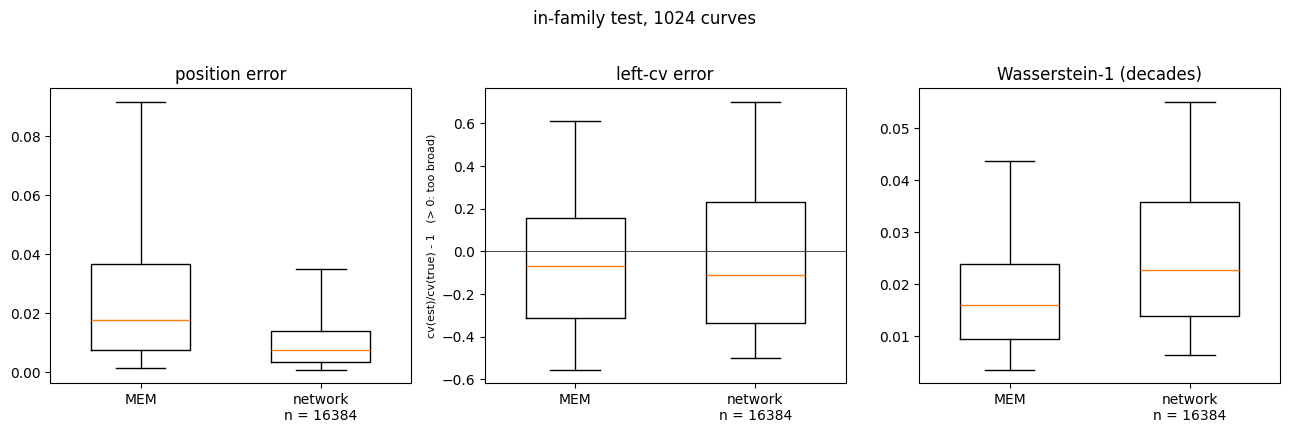

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, k in zip(axes, names):
    data_k = [m_mem[k][~np.isnan(m_mem[k])], m_nn[(n_big, s0)][k][~np.isnan(m_nn[(n_big, s0)][k])]]
    ax.boxplot(data_k, whis=(5, 95), showfliers=False, widths=0.55, tick_labels=["MEM", f"network\nn = {n_big}"])
    ax.set_title(names[k]); ax.axhline(0, color='k', lw=0.5) if k == "cv" else None
axes[1].set_ylabel("cv(est)/cv(true) - 1   (> 0: too broad)", fontsize=8)
plt.suptitle(f"in-family test, {n_eval} curves", y=1.02)
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/gfbr_eval_boxplots.png", dpi=130, bbox_inches="tight"); plt.show()

## Figure 2: learning curve
Median error over the test curves against the number of training curves. Line = mean over seeds of the median, band = min to max over seeds. MEM does not train, so it is a flat line.

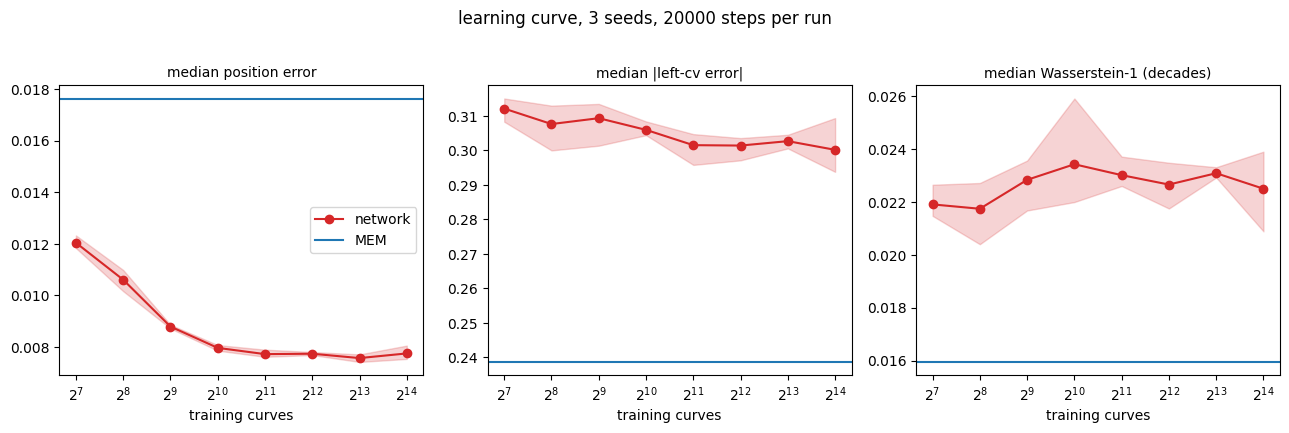

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, k in zip(axes, names):
    f = (lambda v: np.nanmedian(np.abs(v))) if k == "cv" else (lambda v: np.nanmedian(v))
    nn_med = np.array([[f(m_nn[(n, s)][k]) for s in seeds] for n in sizes])        # (sizes, seeds)
    ax.plot(sizes, nn_med.mean(1), 'o-', color='tab:red', label='network')
    ax.fill_between(sizes, nn_med.min(1), nn_med.max(1), color='tab:red', alpha=0.2)
    ax.axhline(f(m_mem[k]), color='tab:blue', label='MEM')
    ax.set_xscale('log', base=2); ax.set_xlabel("training curves"); ax.set_title(("median |left-cv error|" if k == "cv" else "median " + names[k]), fontsize=10)
axes[0].legend()
plt.suptitle(f"learning curve, {len(seeds)} seeds, {steps} steps per run", y=1.02)
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/gfbr_eval_learning_curve.png", dpi=130, bbox_inches="tight"); plt.show()

## Figure 3: error against peak position
Test curves binned by true peak position `R0` (8 log-spaced bins, 3 to 300 nm); median Wasserstein-1 and median position error per bin, MEM and network (largest `n`, seed 0). Shows whether either method fails at the edges of the range.

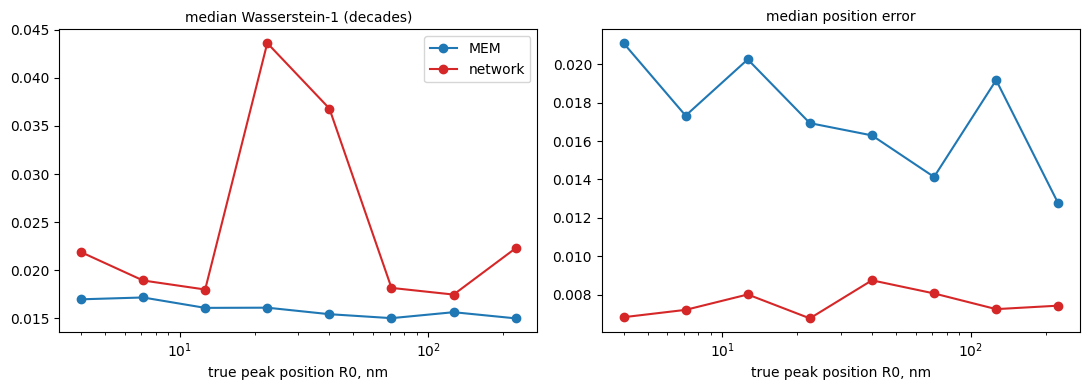

In [8]:
edges = np.geomspace(3e-9, 300e-9, 9); centers = np.sqrt(edges[:-1]*edges[1:])
b = np.clip(np.digitize(R0_test, edges) - 1, 0, 7)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, ["w1", "pos"]):
    for lab, m, col in [("MEM", m_mem, "tab:blue"), ("network", m_nn[(n_big, s0)], "tab:red")]:
        ax.semilogx(centers*1e9, [np.nanmedian(m[k][b == i]) if (b == i).any() else np.nan for i in range(8)], 'o-', color=col, label=lab)
    ax.set_xlabel("true peak position R0, nm"); ax.set_title("median " + names[k], fontsize=10)
axes[0].legend()
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/gfbr_eval_by_R0.png", dpi=130, bbox_inches="tight"); plt.show()

## Figure 4: bimodal test (4 + 16 nm, cv 15%, 70/30; never seen in training)
One noisy curve (the same one as in `gfbr_mem` and `gfbr_nn_naive`). MEM uses `iz` from the single-exponential fit, as in `gfbr_mem`. The network lines are the seeds of the largest training size.


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



MEM bimodal: Solve_Succeeded
true             peak 1: mass 0.70, mode 4.0 nm, left-cv 0.129 | peak 2: mass 0.30, mode 15.7 nm, left-cv 0.122
MEM              peak 1: mass 0.72, mode 4.1 nm, left-cv 0.135 | peak 2: mass 0.28, mode 16.4 nm, left-cv 0.082
network seed 0   peak 1: mass 0.92, mode 6.3 nm, left-cv 0.105 | peak 2: mass 0.08, mode 8.0 nm, left-cv nan
network seed 1   peak 1: mass 0.92, mode 6.3 nm, left-cv 0.129 | peak 2: mass 0.08, mode 8.0 nm, left-cv nan
network seed 2   peak 1: mass 0.94, mode 6.3 nm, left-cv 0.126 | peak 2: mass 0.06, mode 8.0 nm, left-cv nan


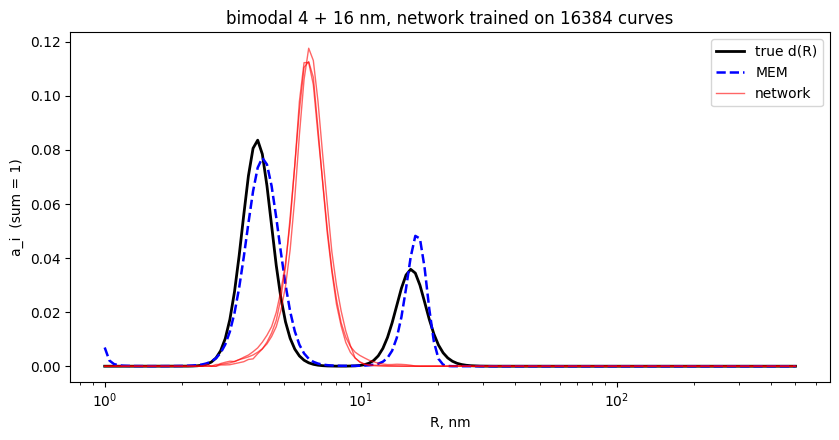

In [9]:
iz_b = iz_from_fit(tau, data["g1_full_bi"][kb])
a_b, cb_b, st_b = mem_one((K_np, x_bi, int(data["ic_bi"][kb]), iz_b, factor))
print("MEM bimodal:", st_b)

split = np.sqrt(float(data["bi_R1"])*float(data["bi_R2"]))
curves = [("true", d_bi)] + [("MEM", a_b)] + [(f"network seed {s}", cache[f"bi_{n_big}_{s}"]) for s in seeds]
for lab, p in curves:
    parts = []
    for pk, lo, hi in [("peak 1", 0.0, split), ("peak 2", split, np.inf)]:
        sel = (R >= lo) & (R < hi); rp, cv = left_cv(p, lo, hi)
        parts.append(f"{pk}: mass {p[sel].sum():.2f}, mode {rp*1e9:.1f} nm, left-cv {cv:.3f}")
    print(f"{lab:16s} " + " | ".join(parts))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.semilogx(R*1e9, d_bi, 'k-', lw=2, label='true d(R)')
ax.semilogx(R*1e9, a_b, 'b--', lw=1.8, label='MEM')
for s in seeds:
    ax.semilogx(R*1e9, cache[f"bi_{n_big}_{s}"], 'r-', lw=1, alpha=0.6, label='network' if s == seeds[0] else None)
ax.set_xlabel("R, nm"); ax.set_ylabel("a_i  (sum = 1)"); ax.legend(); ax.set_title(f"bimodal 4 + 16 nm, network trained on {n_big} curves")
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/gfbr_eval_bimodal.png", dpi=130); plt.show()

## Figure 5: out-of-family family (bimodal, R2 = 4 R1, 128 distributions)
`R1` log-uniform from 3 to 10 nm, `R2 = 4*R1`, cv 15%, weights 70/30; never seen in training. One noise realization per curve. MEM uses `iz` from the single-exponential fit (as for the bimodal example above), cached in `gfbr_mem_ood.npz`. The network is the largest training size, all seeds.

Per curve, with `split = 2*R1` (geometric midpoint of the two peaks):

- *mass of peak 2* = mass of the output at `R >= split` (true value 0.30);
- *position error* of each peak = interpolated position of the maximum on its side of `split` against the true position;
- *recovered* = peak-2 mass above 0.15 **and** peak-2 position within 15% of the truth (same thresholds for both methods);
- Wasserstein-1 against the true distribution.

In [10]:
def side_peak_pos(p, lo, hi):
    # interpolated peak position inside [lo, hi): same parabola through ln(a) as peak_pos, restricted to the side
    sel = np.where((R >= lo) & (R < hi))[0]; ip = sel[np.argmax(p[sel])]
    if ip == sel[0] or ip == sel[-1]: return R[ip]
    y0, y1, y2 = np.log(p[ip - 1] + 1e-300), np.log(p[ip]), np.log(p[ip + 1] + 1e-300)
    den = y0 - 2*y1 + y2
    delta = 0.5*(y0 - y2)/den if den < 0 else 0.0
    return R[ip]*(R[1]/R[0])**np.clip(delta, -0.5, 0.5)

def ood_metrics(est):
    out = dict(mass2=[], pos1=[], pos2=[])
    for p, d, r1 in zip(est, d_ood, R1_ood):
        sp = 2*r1
        out["mass2"].append(p[R >= sp].sum())
        out["pos1"].append(abs(side_peak_pos(p, 0, sp) - r1)/r1)
        out["pos2"].append(abs(side_peak_pos(p, sp, np.inf) - 4*r1)/(4*r1))
    out = {k: np.array(v) for k, v in out.items()}
    out["w1"] = np.abs(np.cumsum(est, axis=1) - np.cumsum(d_ood, axis=1)).sum(axis=1)*dlog
    out["recovered"] = (out["mass2"] > 0.15) & (out["pos2"] < 0.15)
    return out

# MEM on the family (cached)
a_ood = None
if use_cache and os.path.exists("gfbr_mem_ood.npz"):
    c = np.load("gfbr_mem_ood.npz")
    if c["a"].shape[0] == len(d_ood) and float(c["factor"]) == factor: a_ood, status_ood = c["a"], c["status"]; print("MEM (ood) loaded from cache")
if a_ood is None:
    tasks = [(K_np, x_ood[i], int(ic_ood[i]), iz_from_fit(tau, g1f_ood[i]), factor) for i in range(len(d_ood))]
    res = run_mem(tasks)
    a_ood = np.array([r[0] for r in res]); status_ood = np.array([r[2] for r in res])
    np.savez("gfbr_mem_ood.npz", a=a_ood, status=status_ood, factor=factor)
print("MEM status:", {s: int((status_ood == s).sum()) for s in set(status_ood)})

m_ood_mem = ood_metrics(a_ood)
m_ood_nn  = {s: ood_metrics(cache[f"ood_{n_big}_{s}"]) for s in seeds}

def row(lab, m_list):
    v = lambda k: np.mean([np.median(m[k]) for m in m_list])
    return f"{lab:20s} peak-2 mass {v('mass2'):.2f} | position error peak 1 {v('pos1'):.3f}, peak 2 {v('pos2'):.3f} | W1 {v('w1'):.3f} | recovered {100*np.mean([m['recovered'].mean() for m in m_list]):.0f}%"
print("true: peak-2 mass 0.30")
print(row("MEM", [m_ood_mem])); print(row(f"network, n = {n_big}", list(m_ood_nn.values())))
print("network recovered per seed:", [f"{100*m['recovered'].mean():.0f}%" for m in m_ood_nn.values()])

MEM (ood) loaded from cache
MEM status: {np.str_('Solve_Succeeded'): 128}
true: peak-2 mass 0.30
MEM                  peak-2 mass 0.32 | position error peak 1 0.040, peak 2 0.058 | W1 0.032 | recovered 95%
network, n = 16384   peak-2 mass 0.06 | position error peak 1 0.546, peak 2 0.490 | W1 0.208 | recovered 0%
network recovered per seed: ['0%', '0%', '0%']


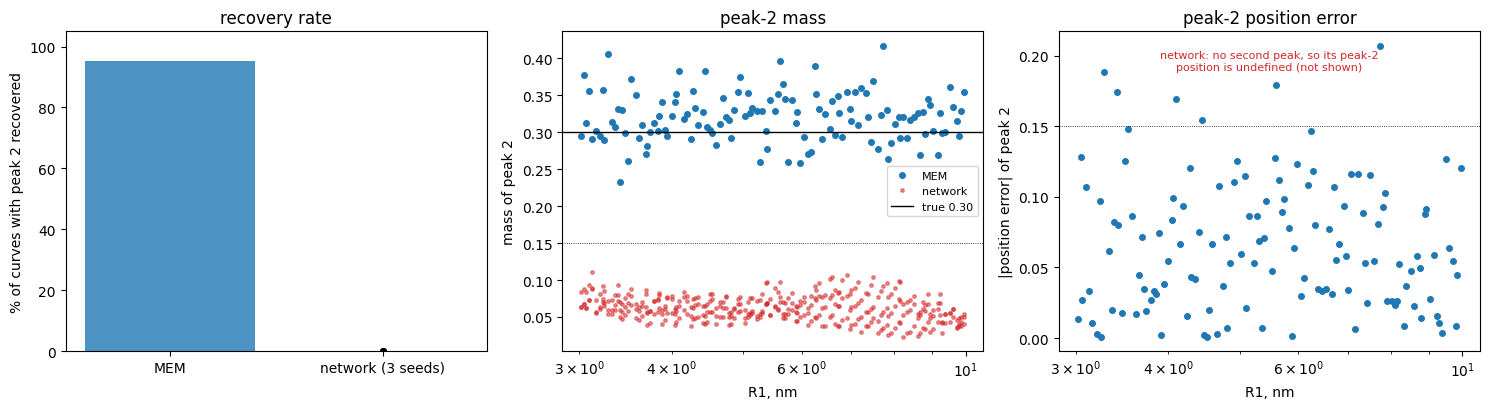

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# (a) recovery rate
rates = [100*m_ood_mem["recovered"].mean()] + [100*m["recovered"].mean() for m in m_ood_nn.values()]
axes[0].bar(["MEM", "network (3 seeds)"], [rates[0], np.mean(rates[1:])], color=["tab:blue", "tab:red"], alpha=0.8)
axes[0].plot([1]*len(seeds), rates[1:], 'ko', ms=4); axes[0].set_ylim(0, 105); axes[0].set_ylabel("% of curves with peak 2 recovered"); axes[0].set_title("recovery rate")
# (b) peak-2 mass against R1
axes[1].semilogx(R1_ood*1e9, m_ood_mem["mass2"], 'o', color="tab:blue", ms=4, label="MEM")
for s_ in seeds: axes[1].semilogx(R1_ood*1e9, m_ood_nn[s_]["mass2"], '.', color="tab:red", alpha=0.5, ms=5, label="network" if s_ == seeds[0] else None)
axes[1].axhline(0.30, color='k', lw=1, label="true 0.30"); axes[1].axhline(0.15, color='k', lw=0.6, ls=':')
axes[1].set_xlabel("R1, nm"); axes[1].set_ylabel("mass of peak 2"); axes[1].set_title("peak-2 mass"); axes[1].legend(fontsize=8)
# (c) peak-2 position error against R1
axes[2].semilogx(R1_ood*1e9, m_ood_mem["pos2"], 'o', color="tab:blue", ms=4)
axes[2].text(0.5, 0.88, "network: no second peak, so its peak-2\nposition is undefined (not shown)", transform=axes[2].transAxes, ha="center", fontsize=8, color="tab:red")
axes[2].axhline(0.15, color='k', lw=0.6, ls=':'); axes[2].set_xlabel("R1, nm"); axes[2].set_ylabel("|position error| of peak 2"); axes[2].set_title("peak-2 position error")
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/gfbr_eval_ood.png", dpi=130, bbox_inches="tight"); plt.show()